# Serre 100 — 21 · Les opérateurs de Hecke, calculés

*Série [Serre 100](../README.md) — EPIC [#16334](https://github.com/jsboige/CoursIA/issues/16334).*

Ce carnet prend un objet central de l'œuvre arithmétique de Serre — l'action des **opérateurs de Hecke** sur les formes modulaires — et le rend **calculable** : chaque énoncé devient un calcul exact sur des q-développements tronqués, et chaque résultat est confronté à une seconde route indépendante.

Le geste est le même que dans les carnets 11 à 17 : rien n'est affirmé sur la foi du texte. Une propriété des opérateurs de Hecke qui ne serait pas **mesurée** ici est signalée comme **citée**, jamais comme vérifiée.

## Ce que le carnet mesure, et ce qu'il ne mesure pas

| Propriété | Statut ici | Comment |
|---|---|---|
| `E4`, `E6` ont des coefficients entiers (séries de diviseurs) | **mesuré** | calcul direct |
| `dim M_k`, `dim S_k` | **mesuré** | deux routes : formule classique, puis comptage de monômes |
| `Delta = (E4^3 - E6^2)/1728` est à coefficients entiers | **mesuré** | division exacte, reste vérifié à chaque coefficient |
| `Delta = q * prod (1 - q^n)^24` | **mesuré** | produit d'Euler, comparé terme à terme à la route précédente |
| `T_p(E_k) = (1 + p^(k-1)) E_k` | **mesuré** | image calculée comparée au multiple attendu |
| `T_p(Delta) = tau(p) * Delta` | **mesuré** | proportionnalité coefficient par coefficient |
| `[T_p, T_q] = 0` et `T_{pq} = T_p T_q` sur `S_24` | **mesuré** | matrices entières 2×2, produits exacts |
| `T_{p^2} = T_p^2 - p^(k-1)` | **mesuré** | idem, arithmétique entière |
| `|trace T_p| <= 4 p^{11.5}` et `|det T_p| <= 4 p^{23}` sur `S_24` | **mesuré** | déterminant et trace des matrices ; `det = p^{23}` est **faux** et le carnet le montre |
| borne de Deligne `|tau(p)| <= 2 p^(11/2)` | **mesuré** sur `p <= 800` | test direct |
| distribution de Sato–Tate des angles `theta_p` | **exploré** | distance sup à deux lois de référence ; le nombre de premiers est petit, ce n'est pas un test de preuve |
| les théorèmes eux-mêmes (Deligne 1974, Sato–Tate) | **cité** | aucune preuve ici — le carnet mesure des cas |

**Limite assumée** : tous les calculs sont tronqués à `q^800`. Un accord sur 800 coefficients n'est pas une démonstration ; c'est un témoin. La généralisation est le rôle du versant Lean (`serre100_lean/`) et de la littérature citée.

## 1. Les séries d'Eisenstein, en arithmétique entière

Les deux formes de niveau 1 dont tout part :

$$E_4(q) = 1 + 240\sum_{n\geq 1}\sigma_3(n)\,q^n, \qquad E_6(q) = 1 - 504\sum_{n\geq 1}\sigma_5(n)\,q^n$$

où `sigma_k(n)` est la somme des `k`-ièmes puissances des diviseurs de `n`. Les coefficients sont donc **entiers** et se calculent par un crible de diviseurs, sans flottants.

In [1]:
N_MAX = 800  # degre maximal conserve dans les q-developpements


def table_sigma(n_max, puissance):
    """Somme des diviseurs eleves a `puissance`, pour n <= n_max (crible)."""
    s = [0] * (n_max + 1)
    for d in range(1, n_max + 1):
        v = d ** puissance
        for m in range(d, n_max + 1, d):
            s[m] += v
    return s


def mul(a, b, n_max):
    """Produit tronque de deux series a coefficients entiers."""
    out = [0] * (n_max + 1)
    for i, ai in enumerate(a):
        if ai == 0 or i > n_max:
            continue
        limite = min(len(b) - 1, n_max - i)
        for j in range(limite + 1):
            out[i + j] += ai * b[j]
    return out


def tronque(f, n_max):
    return (list(f) + [0] * (n_max + 1))[: n_max + 1]


SIGMA3 = table_sigma(N_MAX, 3)
SIGMA5 = table_sigma(N_MAX, 5)

E4 = [1] + [240 * SIGMA3[n] for n in range(1, N_MAX + 1)]
E6 = [1] + [-504 * SIGMA5[n] for n in range(1, N_MAX + 1)]

print("E4 :", E4[:7])
print("E6 :", E6[:7])
print("degre conserve : q^%d" % N_MAX)
assert E4[0] == 1 and E6[0] == 1
assert E4[1] == 240 * 1 and E6[1] == -504 * 1

E4 : [1, 240, 2160, 6720, 17520, 30240, 60480]
E6 : [1, -504, -16632, -122976, -532728, -1575504, -4058208]
degre conserve : q^800


### Lecture du résultat

Les deux séries commencent bien par `1` (le terme constant) et leurs premiers coefficients sont ceux des formules imprimées : `240 sigma_3(1) = 240`, `-504 sigma_5(1) = -504`, puis `240 sigma_3(2) = 240 * 9 = 2160` pour `E4` et `-504 * 33 = -16632` pour `E6`.

Rien n'est arrondi nulle part : tout ce carnet reste dans les entiers de Python, qui ne débordent pas. C'est ce qui rend possible la vérification **exacte** de la section 5, où des comparaisons de matrices flottantes ne prouveraient rien.

## 2. La dimension des espaces, par deux routes

Une forme modulaire de niveau 1 et de poids `k` s'écrit de façon unique comme polynôme en `E4` et `E6` ; les formes paraboliques sont exactement les multiples de

$$\Delta = \frac{E_4^3 - E_6^2}{1728} \in S_{12}.$$

D'où deux façons indépendantes de compter les dimensions :

1. la **formule classique** `dim M_k = floor(k/12) + 1` sauf si `k = 2 (mod 12)` où l'on retire 1 ;
2. le **comptage de monômes** `E4^a E6^b` de poids `4a + 6b = k`, et, pour les formes paraboliques, le comptage des monômes de poids `k - 12` (l'espace `Delta * M_{k-12}`).

Si les deux routes sont d'accord sur toute une plage de poids, la formule n'est pas seulement récitée : elle est reproduite par un comptage.

In [2]:
def dim_M_formule(k):
    """Dimension de M_k : formule classique (forme d'Eisenstein comprise)."""
    if k < 0 or k % 2 == 1:
        return 0
    if k % 12 == 2:
        return k // 12
    return k // 12 + 1


def monomes(k):
    """Nombre de couples (a, b) d'entiers >= 0 tels que 4a + 6b = k."""
    total = 0
    for b in range(k // 6 + 1):
        reste = k - 6 * b
        if reste >= 0 and reste % 4 == 0:
            total += 1
    return total


def dim_S_deux_routes(k):
    """dim S_k : par soustraction a M_k, et par comptage des monomes de poids k-12."""
    if k < 0 or k % 2 == 1:
        return 0, 0
    # M_k = S_k (+) C*E_k : la forme d'Eisenstein manque exactement quand k = 2 (mod 12),
    # c'est-a-dire pour k = 2 ou k >= 14 ; pour k = 0 il n'y a pas de forme d'Eisenstein
    # mais le terme constant compte comme une dimension, d'ou la soustraction.
    par_soustraction = dim_M_formule(k) - (0 if k == 2 else 1)
    par_monomes = monomes(k - 12) if k >= 12 else 0
    return par_soustraction, par_monomes


desaccords = []
print("%3s %8s %8s %8s %13s" % ("k", "dim M_k", "monomes", "dim S_k", "Delta*M_k-12"))
for k in range(0, 61, 2):
    dM, m = dim_M_formule(k), monomes(k)
    dS, dS_bis = dim_S_deux_routes(k)
    print("%3d %8d %8d %8d %13d" % (k, dM, m, dS, dS_bis))
    if dM != m or dS != dS_bis:
        desaccords.append((k, dM, m, dS, dS_bis))
print("desaccords entre les deux routes :", desaccords)
assert not desaccords, desaccords

  k  dim M_k  monomes  dim S_k  Delta*M_k-12
  0        1        1        0             0
  2        0        0        0             0
  4        1        1        0             0
  6        1        1        0             0
  8        1        1        0             0
 10        1        1        0             0
 12        2        2        1             1
 14        1        1        0             0
 16        2        2        1             1
 18        2        2        1             1
 20        2        2        1             1
 22        2        2        1             1
 24        3        3        2             2
 26        2        2        1             1
 28        3        3        2             2
 30        3        3        2             2
 32        3        3        2             2
 34        3        3        2             2
 36        4        4        3             3
 38        3        3        2             2
 40        4        4        3             3
 42       

### Lecture du résultat

La colonne `monomes` reproduit `dim M_k` sur toute la plage, et `Delta*M_k-12` reproduit `dim S_k` — y compris les deux lignes limites `k = 0` et `k = 2`, où le nombre de formes d'Eisenstein n'est pas celui qu'un `+1` naïf laisserait attendre.

Le cas qui porte le contenu est `k = 2 (mod 12)` (poids 14, 26, 38, 50) : c'est le seul où la formule perd son `+1`. Pour `k = 14`, un seul monôme a le bon poids — `E4^2 * E6`, puisque `4*2 + 6*1 = 14` — donc `dim M_14 = 1 = 14 // 12`. Et comme `S_14 = Delta * M_2` avec `dim M_2 = 0`, l'espace parabolique de poids 14 est **nul** : une forme modulaire existe, aucune forme parabolique. C'est exactement la distinction que la double route rend visible.

## 3. `Delta` par deux routes indépendantes

La définition `Delta = (E4^3 - E6^2)/1728` n'est utilisable que si la division **tombe juste** coefficient par coefficient. C'est une propriété arithmétique réelle, pas une convention : on la vérifie au lieu de la supposer.

La seconde route est le produit d'Euler, qui ne fait intervenir ni `E4` ni `E6` :

$$\Delta(q) = q\prod_{n\geq 1}(1-q^n)^{24}.$$

Deux calculs sans un seul terme commun : s'ils coïncident sur 800 coefficients, ce n'est pas une coïncidence d'arrondi, c'est le même objet.

In [3]:
E4_carre = mul(E4, E4, N_MAX)
E4_cube = mul(E4_carre, E4, N_MAX)
E6_carre = mul(E6, E6, N_MAX)

brut = [E4_cube[n] - E6_carre[n] for n in range(N_MAX + 1)]
non_divisibles = [n for n in range(N_MAX + 1) if brut[n] % 1728 != 0]
print("terme constant de E4^3 - E6^2 :", brut[0])
print("coefficients non divisibles par 1728 : %d" % len(non_divisibles))
assert brut[0] == 0
assert not non_divisibles, non_divisibles[:5]

DELTA = [brut[n] // 1728 for n in range(N_MAX + 1)]
print("Delta (route Eisenstein) :", DELTA[1:10])

terme constant de E4^3 - E6^2 : 0
coefficients non divisibles par 1728 : 0
Delta (route Eisenstein) : [1, -24, 252, -1472, 4830, -6048, -16744, 84480, -113643]


In [4]:
from math import comb


def produit_euler(n_max, exposant=24):
    """q * prod_{n>=1} (1 - q^n)^exposant, tronque a q^n_max."""
    produit = [1] + [0] * n_max
    for n in range(1, n_max + 1):
        facteur = []
        for j in range(exposant + 1):
            if n * j > n_max:
                break
            facteur.append((n * j, ((-1) ** j) * comb(exposant, j)))
        nouveau = [0] * (n_max + 1)
        for i, ai in enumerate(produit):
            if ai == 0:
                continue
            for j, bj in facteur:
                if bj == 0 or i + j > n_max:
                    continue
                nouveau[i + j] += ai * bj
        produit = nouveau
    return [0] + produit[:n_max]


DELTA_PRODUIT = produit_euler(N_MAX, 24)
ecarts = [n for n in range(1, N_MAX + 1) if DELTA[n] != DELTA_PRODUIT[n]]
print("Delta (route produit d'Euler) :", DELTA_PRODUIT[1:10])
print("ecarts entre les deux routes sur n <= %d : %d" % (N_MAX, len(ecarts)))
print("premiers ecarts :", ecarts[:5])
assert not ecarts, ecarts[:5]

Delta (route produit d'Euler) : [1, -24, 252, -1472, 4830, -6048, -16744, 84480, -113643]
ecarts entre les deux routes sur n <= 800 : 0
premiers ecarts : []


### Lecture du résultat

La division par `1728` tombe juste sur **tous** les coefficients calculés, et les deux routes donnent la même série.

Le début `1, -24, 252, -1472, 4830, -6048, ...` est la suite de Ramanujan `tau(n)`. Elle est ici **calculée deux fois** : comme quotient de deux séries d'Eisenstein, et comme produit d'Euler. La suite du carnet utilise indifféremment l'une ou l'autre, et c'est précisément ce qui rend les vérifications de la section suivante non circulaires.

## 4. L'opérateur `T_p`, défini sur les q-développements

Pour une forme de poids `k`, l'opérateur de Hecke `T_p` agit sur les coefficients par

$$(T_p f)_n = a_{pn} + p^{k-1} a_{n/p}$$

(le second terme n'existe que si `p` divise `n`). Aucune théorie n'est nécessaire pour l'implémenter : c'est une formule sur des listes d'entiers. Ce qui est intéressant, c'est ce qu'elle **fait** aux formes qu'on connaît.

Deux vérifications indépendantes :

1. sur les séries d'Eisenstein, `T_p(E_k)` doit être le multiple `(1 + p^{k-1}) E_k` — une valeur propre connue ;
2. sur `Delta`, `T_p(Delta)` doit être **proportionnel** à `Delta`, le facteur étant `tau(p)` — lu sur la *route produit d'Euler*, donc jamais sur la même série que celle qui subit l'opérateur.

In [5]:
def hecke(f, p, poids, n_max):
    """(T_p f)_n = a_{pn} + p^(poids-1) * a_{n/p}, pour n <= n_max."""
    pk1 = p ** (poids - 1)
    out = [0] * (n_max + 1)
    for n in range(n_max + 1):
        v = f[p * n] if p * n < len(f) else 0
        if n % p == 0:
            v += pk1 * f[n // p]
        out[n] = v
    return out


def est_premier(n):
    if n < 2:
        return False
    q = 2
    while q * q <= n:
        if n % q == 0:
            return False
        q += 1
    return True


PREMIERS = [p for p in range(2, 30) if est_premier(p)]

valeurs_propres_ok = []
for p in PREMIERS:
    for f, poids, lam in ((E4, 4, 1 + p ** 3), (E6, 6, 1 + p ** 5)):
        image = hecke(f, p, poids, 20)
        attendu = [lam * c for c in tronque(f, 20)]
        valeurs_propres_ok.append(image == attendu)
print("T_p(E4) = (1 + p^3) E4 et T_p(E6) = (1 + p^5) E6 sur p in", PREMIERS)
print("les %d comparaisons sont exactes : %s" % (len(valeurs_propres_ok), all(valeurs_propres_ok)))
assert all(valeurs_propres_ok)

for p in PREMIERS:
    n_max = N_MAX // p
    image = hecke(DELTA, p, 12, n_max)
    tau_p = DELTA_PRODUIT[p]
    attendu = [tau_p * c for c in tronque(DELTA, n_max)]
    ok = image == attendu
    print("p = %2d  tau(p) = %14d  T_p(Delta) = tau(p) * Delta : %s" % (p, tau_p, ok))
    assert ok, p

T_p(E4) = (1 + p^3) E4 et T_p(E6) = (1 + p^5) E6 sur p in [2, 3, 5, 7, 11, 13, 17, 19, 23, 29]
les 20 comparaisons sont exactes : True
p =  2  tau(p) =            -24  T_p(Delta) = tau(p) * Delta : True
p =  3  tau(p) =            252  T_p(Delta) = tau(p) * Delta : True
p =  5  tau(p) =           4830  T_p(Delta) = tau(p) * Delta : True
p =  7  tau(p) =         -16744  T_p(Delta) = tau(p) * Delta : True
p = 11  tau(p) =         534612  T_p(Delta) = tau(p) * Delta : True
p = 13  tau(p) =        -577738  T_p(Delta) = tau(p) * Delta : True
p = 17  tau(p) =       -6905934  T_p(Delta) = tau(p) * Delta : True
p = 19  tau(p) =       10661420  T_p(Delta) = tau(p) * Delta : True
p = 23  tau(p) =       18643272  T_p(Delta) = tau(p) * Delta : True
p = 29  tau(p) =      128406630  T_p(Delta) = tau(p) * Delta : True


### Lecture du résultat

Les séries d'Eisenstein sont bien des vecteurs propres de `T_p`, avec les valeurs propres `1 + p^3` et `1 + p^5` : le calcul le vérifie sur les dix premiers nombres premiers.

Cette propriété est **indépendante** du fait qu'elles ne soient pas paraboliques — elle ne l'explique pas. Témoin immédiat, mesuré par la cellule précédente : `Delta` est forme propre de **tous** les `T_p` et c'est une forme parabolique. Être vecteur propre décrit l'action de `T_p` ; être parabolique décrit le **terme constant**, nul pour une forme parabolique et égal à `1` pour `E_4` comme pour `E_6` (section 1). Le sous-espace parabolique a déjà sa forme générale depuis la section 2, `S_k = Delta * M_{k-12}` : aux poids 4 et 6, `k - 12 < 0`, donc `S_4 = S_6 = {0}` et il n'y a là aucune forme parabolique à engendrer.

Et `T_p(Delta)` est un multiple exact de `Delta` : `Delta` est donc une **forme propre de tous les `T_p`**, ce que la théorie annonce et ce que la mesure confirme. La valeur propre est `tau(p)`, lue sur la route du produit d'Euler : les deux calculs sont indépendants par construction.

C'est le fait dont tout le reste dépend. Une forme propre de tous les opérateurs de Hecke porte une fonction `L` avec un produit d'Euler, et ses coefficients héritent d'une structure multiplicative — c'est l'objet de la section 6.


## 5. L'algèbre de Hecke sur `S_24`, en matrices entières

`S_24` est de dimension 2 : deux formes paraboliques, et aucune base privilégiée. Une base commode est

$$B_1 = \Delta \cdot E_4^3, \qquad B_2 = \Delta \cdot E_6^2,$$

toutes deux de poids `12 + 12 = 24`. On calcule l'image de chaque vecteur de base par `T_p`, puis on **résout** l'expression de cette image dans la base — en arithmétique rationnelle exacte, avec vérification sur *tous* les coefficients disponibles, pas seulement sur ceux qui ont servi à résoudre. Une matrice n'est retenue que si la combinaison reproduit l'image partout ; sinon le calcul lève.

C'est ce qui permet de tester des identités d'opérateurs comme des identités de matrices : `[T_p, T_q] = 0`, `T_{pq} = T_p T_q`, `T_{p^2} = T_p^2 - p^{23}`.

Pour tester `T_{pq}` il faut `T_m` avec `m` **composé**, et la formule de la section 4 n'y suffit pas : elle suppose `m` premier. La formule générale est

$$(T_m f)_n = \sum_{d \mid \gcd(m, n)} d^{k-1} a_{mn/d^2},$$

et le carnet vérifie qu'elle redonne bien la formule première quand `m` est premier — sans quoi on comparerait deux choses différentes et l'identité `T_{pq} = T_p T_q` ne prouverait rien.

In [6]:
from fractions import Fraction
from math import gcd

POIDS_24 = 24
BASE = [mul(DELTA, E4_cube, N_MAX), mul(DELTA, E6_carre, N_MAX)]
print("B1 = Delta*E4^3 :", BASE[0][1:6])
print("B2 = Delta*E6^2 :", BASE[1][1:6])


def choisir_positions(base, n_max):
    """Deux rangs ou le mineur de la base est non nul (resolution exacte)."""
    for i in range(1, n_max):
        for j in range(i + 1, n_max + 1):
            if base[0][i] * base[1][j] - base[0][j] * base[1][i] != 0:
                return (i, j)
    raise AssertionError("base de rang < 2 sur la troncature")


POSITIONS = choisir_positions(BASE, N_MAX)
print("rangs utilises pour resoudre :", POSITIONS)


def coordonnees(v, base, n_max, positions):
    """v = alpha*base[0] + beta*base[1], resolu puis verifie partout."""
    i, j = positions
    det = base[0][i] * base[1][j] - base[0][j] * base[1][i]
    alpha = Fraction(v[i] * base[1][j] - v[j] * base[1][i], det)
    beta = Fraction(base[0][i] * v[j] - base[0][j] * v[i], det)
    for n in range(n_max + 1):
        if alpha * base[0][n] + beta * base[1][n] != v[n]:
            raise AssertionError("coefficient hors base : %d" % n)
    return alpha, beta


def diviseurs(n):
    return [d for d in range(1, n + 1) if n % d == 0]


def hecke_entier(f, m, poids, n_max):
    """(T_m f)_n = somme_{d | pgcd(m,n)} d^(poids-1) * a_{mn/d^2}, n <= n_max.

    C'est la formule generale, valable pour m compose ; pour m premier elle se
    reduit a a_{mn} + m^(poids-1) a_{n/m}, ce que le carnet verifie plus bas.
    """
    out = [0] * (n_max + 1)
    for n in range(n_max + 1):
        total = 0
        for d in diviseurs(gcd(m, n)):
            indice = m * n // (d * d)
            if indice < len(f):
                total += d ** (poids - 1) * f[indice]
        out[n] = total
    return out


# la formule generale doit coincider avec la formule premiere quand m est premier
coincidences = [hecke_entier(BASE[0], p, POIDS_24, 40) == hecke(BASE[0], p, POIDS_24, 40)
                for p in [2, 3, 5, 7]]
print("formule generale = formule premiere sur m premier :", coincidences)
assert all(coincidences)


def matrice_hecke(m):
    """Matrice 2x2 de T_m dans la base (B1, B2), arithmetique exacte."""
    n_max = N_MAX // m
    colonnes = [coordonnees(hecke_entier(f, m, POIDS_24, n_max), BASE, n_max, POSITIONS)
                for f in BASE]
    assert all(c.denominator == 1 for col in colonnes for c in col), m
    return ((int(colonnes[0][0]), int(colonnes[1][0])),
            (int(colonnes[0][1]), int(colonnes[1][1])))


MATRICES = {p: matrice_hecke(p) for p in [2, 3, 5, 7, 11, 13]}
for p, M in MATRICES.items():
    print("T_%-2d = [[%d, %d], [%d, %d]]" % (p, M[0][0], M[0][1], M[1][0], M[1][1]))

B1 = Delta*E4^3 : [1, 696, 162252, 12831808, 34188270]
B2 = Delta*E6^2 : [1, -1032, 245196, 10965568, 60177390]
rangs utilises pour resoudre : (1, 2)
formule generale = formule premiere sur m premier : [True, True, True, True]
T_2  = [[12696, 10584], [-12000, -11616]]
T_3  = [[-413748, -508032], [576000, 753228]]
T_5  = [[-146291730, -159183360], [180480000, 219360750]]
T_7  = [[-12663268744, -10433961216], [11829888000, 11304084344]]
T_11 = [[898492953732, 409300214400], [-464059200000, -41690985468]]
T_13 = [[17606120567462, 13424219278848], [-15220203264000, -13230011245402]]


In [7]:
def matmul(A, B):
    return tuple(tuple(sum(A[i][k] * B[k][j] for k in range(2)) for j in range(2))
                 for i in range(2))


commutations = []
for p in [2, 3, 5, 7]:
    for q in [3, 5, 7, 11]:
        if p >= q:
            continue
        commutations.append((p, q, matmul(MATRICES[p], MATRICES[q]) ==
                             matmul(MATRICES[q], MATRICES[p])))
print("commutation [T_p, T_q] = 0 :", commutations)

multiplicativite = []
for p in [2, 3, 5]:
    for q in [3, 5, 7]:
        if p >= q:
            continue
        produit = matmul(MATRICES[p], MATRICES[q])
        direct = matrice_hecke(p * q)
        multiplicativite.append((p, q, produit == direct))
print("T_{pq} = T_p T_q pour p != q :", multiplicativite)
assert all(ok for _, _, ok in commutations)
assert all(ok for _, _, ok in multiplicativite)

recurrence = []
for p in [2, 3, 5]:
    carre = matmul(MATRICES[p], MATRICES[p])
    attendu = ((carre[0][0] - p ** 23, carre[0][1]),
               (carre[1][0], carre[1][1] - p ** 23))
    recurrence.append((p, matrice_hecke(p * p) == attendu))
print("T_{p^2} = T_p^2 - p^23 :", recurrence)
assert all(ok for _, ok in recurrence)

commutation [T_p, T_q] = 0 : [(2, 3, True), (2, 5, True), (2, 7, True), (2, 11, True), (3, 5, True), (3, 7, True), (3, 11, True), (5, 7, True), (5, 11, True), (7, 11, True)]
T_{pq} = T_p T_q pour p != q : [(2, 3, True), (2, 5, True), (2, 7, True), (3, 5, True), (3, 7, True), (5, 7, True)]
T_{p^2} = T_p^2 - p^23 : [(2, True), (3, True), (5, True)]


### Lecture du résultat

Les trois identités tiennent **exactement**, sur des matrices entières construites par résolution rationnelle : les opérateurs de Hecke de poids 24 forment bien une algèbre commutative, et la relation de récurrence `T_{p^2} = T_p^2 - p^{23}` n'est pas une convention de définition mais une identité vérifiée.

Le **déterminant** est le point où il faut se méfier d'un réflexe de dimension 1. Pour `Delta`, qui est seule dans `S_12`, `T_p` agit par le scalaire `tau(p)`, donc `det T_p = tau(p)` — `-24` pour `p = 2` — et non `p^{11} = p^{k-1}` : ce dernier produit est le déterminant de **Frobenius**, celui des racines de `X^2 - tau(p) X + p^{11}` que la lecture suivante retrouve. Rien n'autorise à transporter l'un ou l'autre à `S_24` : la cellule suivante affiche les déterminants mesurés, et ils ne valent **pas** `p^{23}`. Ce qui subsiste, et qui est vérifié, c'est l'encadrement que la borne de Deligne impose aux deux valeurs propres.

Une remarque de méthode : la résolution aurait pu « réussir » sur deux coefficients par hasard. C'est pourquoi `coordonnees` vérifie la combinaison sur **tous** les coefficients de la troncature et lève au premier désaccord — un accord partiel n'est pas un accord.

In [8]:
import math

# borne de Deligne appliquee aux DEUX valeurs propres de T_p sur S_24 :
#   |lambda_i| <= 2 p^11.5  =>  |trace| <= 4 p^11.5 et |det| <= 4 p^23
mesures = []
for p, M in sorted(MATRICES.items()):
    t = M[0][0] + M[1][1]
    det = M[0][0] * M[1][1] - M[0][1] * M[1][0]
    disc = t * t - 4 * det
    mesures.append((p, t, det, disc))
    print("p = %2d  trace = %14d  det = %22d  det/p^23 = %+8.4f  discriminant = %24d"
          % (p, t, det, det / p ** 23, disc))

hors_trace = [(p, t / (4 * p ** 11.5)) for p, t, _, _ in mesures if abs(t) > 4 * p ** 11.5]
hors_det = [(p, det / (4 * p ** 23)) for p, _, det, _ in mesures if abs(det) > 4 * p ** 23]
print("traces hors de |t| <= 4 p^11.5 :", hors_trace)
print("determinants hors de |det| <= 4 p^23 :", hors_det)
print("determinants egaux a p^23 :", [p for p, _, det, _ in mesures if det == p ** 23])
print("discriminants positifs (valeurs propres reelles) :",
      [p for p, _, _, disc in mesures if disc > 0])
assert not hors_trace and not hors_det

p =  2  trace =           1080  det =              -20468736  det/p^23 =  -2.4401  discriminant =                 83041344
p =  3  trace =         339480  det =           -19020146544  det/p^23 =  -0.2020  discriminant =             191327256576
p =  5  trace =       73069020  det =      -3361250798797500  det/p^23 =  -0.2820  discriminant =        18784084878950400
p =  7  trace =    -1359184400  det =  -19714065371291135936  det/p^23 =  -0.7203  discriminant =     80703643718367903744
p = 11  trace =   856801968264  det = 152480473377151271633424  det/p^23 =  +0.1703  discriminant = 124187719312459376640000
p = 13  trace =  4376109322060  det = -28609827010851645818437724  det/p^23 =  -0.6852  discriminant = 133589640842027016076394496
traces hors de |t| <= 4 p^11.5 : []
determinants hors de |det| <= 4 p^23 : []
determinants egaux a p^23 : []
discriminants positifs (valeurs propres reelles) : [2, 3, 5, 7, 11, 13]


### Lecture du résultat

Deux choses s'y lisent. D'abord, `det T_p` n'est **pas** `p^{23}` : le réflexe de dimension 1 est faux, et c'est la mesure qui le dit. Ensuite, les deux bornes qui suivent de Deligne sont respectées : `|trace| <= 4 p^{11.5}` et `|det| <= 4 p^{23}`. Elles ne sont pas décoratives — ce sont elles qui garantissent que les deux valeurs propres restent du même ordre de grandeur que `p^{11.5}`.

La dernière ligne est un **constat**, pas une prédiction : les six discriminants mesurés sont **positifs**, donc les valeurs propres de `T_p` sur `S_24` sont réelles pour ces six premiers. Le contraste avec `Delta` est net, mais il faut le nommer correctement : sur `S_12` (dimension 1), `T_p` agit par le scalaire `tau(p)`, une valeur propre **réelle**. Le couple complexe conjugué ne vit pas dans le spectre de `T_p` : il vit dans le **polynôme de Frobenius** `X^2 - tau(p) X + p^{11}`, dont le déterminant `alpha·beta = p^{11}` et la borne `|tau(p)| <= 2 p^{5.5}` forcent `tau(p)^2 - 4 p^{11} <= 0` — deux racines complexes conjuguées, le cadre de Sato–Tate. Deux espaces, deux régimes : valeurs propres réelles de `T_p` sur `S_24`, racines de Frobenius conjuguées pour `Delta`. Le carnet affiche les deux, sans en faire une théorie.


## 6. La borne de Deligne, mesurée sur `tau`

La conjecture de Ramanujan affirme `|tau(p)| <= 2 p^{11/2}`. Elle a été prouvée par Deligne en 1974 comme conséquence des conjectures de Weil — **c'est un théorème, cité ici, pas redémontré**. Ce que le carnet peut faire, c'est la **mesurer** sur tous les nombres premiers de la troncature, et regarder de combien la borne est mordue.

Puis deux structures multiplicatives qui découlent du produit eulérien :

- `tau(mn) = tau(m) tau(n)` pour `m, n` premiers entre eux ;
- `tau(p^{r+1}) = tau(p) tau(p^r) - p^{11} tau(p^{r-1})`.

In [9]:
PRIMES_TRONCATURE = [p for p in range(2, N_MAX + 1) if est_premier(p)]
ratios = sorted((abs(DELTA_PRODUIT[p]) / (2 * p ** 5.5), p) for p in PRIMES_TRONCATURE)

print("nombres premiers utilises : %d" % len(PRIMES_TRONCATURE))
print("ratio |tau(p)| / (2 p^(11/2)) :")
print("  minimum = %.4f (p = %d)" % ratios[0])
print("  median  = %.4f (p = %d)" % ratios[len(ratios) // 2])
print("  maximum = %.4f (p = %d)" % ratios[-1])
print("moyenne = %.4f" % (sum(r for r, _ in ratios) / len(ratios)))
print("borne de Deligne violee :", [p for r, p in ratios if r > 1.0])
assert all(r <= 1.0 for r, _ in ratios)

nombres premiers utilises : 139
ratio |tau(p)| / (2 p^(11/2)) :
  minimum = 0.0055 (p = 617)
  median  = 0.3869 (p = 101)
  maximum = 0.9594 (p = 103)
moyenne = 0.4146
borne de Deligne violee : []


In [10]:
from math import gcd


def multiplicativite_tau(n_max):
    """Vérifie tau(mn) = tau(m) tau(n) pour (m, n) = 1."""
    desaccords = []
    for m in range(1, n_max):
        for n in range(1, n_max // m):
            if gcd(m, n) == 1 and DELTA_PRODUIT[m * n] != DELTA_PRODUIT[m] * DELTA_PRODUIT[n]:
                desaccords.append((m, n))
    return desaccords


def recurrence_tau(p, max_r):
    """Verifie tau(p^(r+1)) = tau(p) tau(p^r) - p^11 tau(p^(r-1))."""
    desaccords = []
    for r in range(1, max_r):
        if p ** (r + 1) > N_MAX:
            break
        gauche = DELTA_PRODUIT[p ** (r + 1)]
        droite = DELTA_PRODUIT[p] * DELTA_PRODUIT[p ** r] - p ** 11 * DELTA_PRODUIT[p ** (r - 1)]
        if gauche != droite:
            desaccords.append((p, r, gauche, droite))
    return desaccords


d1 = multiplicativite_tau(N_MAX)
d2 = [x for p in PRIMES_TRONCATURE[:40] for x in recurrence_tau(p, 12)]
print("multiplicativite tau(mn) = tau(m) tau(n) sur (m, n) = 1, m*n <= %d : %d desaccord(s)"
      % (N_MAX, len(d1)))
print("premiers desaccords :", d1[:3])
print("recurrence de Hecke sur p^(r+1), 40 premiers p : %d desaccord(s)" % len(d2))
print("premiers desaccords :", d2[:3])
assert not d1 and not d2

multiplicativite tau(mn) = tau(m) tau(n) sur (m, n) = 1, m*n <= 800 : 0 desaccord(s)
premiers desaccords : []
recurrence de Hecke sur p^(r+1), 40 premiers p : 0 desaccord(s)
premiers desaccords : []


### Lecture du résultat

La borne tient sur les 139 premiers de la troncature, sans exception. Deux chiffres disent plus qu'un « conforme » : le maximum du rapport vaut `0.9594` (p = 103) — la borne est approchée de très près, ce qui est le comportement attendu à la limite — et le minimum `0.0055` (p = 617), où `tau(p)` est presque nul. Un jeu de ratios tous collés à `1`, ou tous proches de `0`, trahirait un calcul faux ; cette étendue est le témoin interne que la mesure n'est pas faussée.

Les deux structures multiplicatives, elles, tiennent **exactement** : accord sur tous les couples premiers entre eux de la troncature, et sur les récurrences de Hecke des petits nombres premiers. C'est ce que signifie « `Delta` est une forme propre » — non pas une intuition, mais une identité sur les coefficients.

## 7. La distribution des angles : Sato–Tate, explorée

Le rapport `tau(p) / (2 p^{11/2})`, qui vit dans `[-1, 1]` d'après la section 6, définit un angle `theta_p in [0, pi]` par `cos theta_p = tau(p) / (2 p^{11/2})`. La conjecture de Sato–Tate (prouvée depuis, et formulée par Serre dans le cadre général de ses conjectures sur les images de Galois) prédit que ces angles se répartissent selon la mesure

$$\mu_{ST} = \frac{2}{\pi}\sin^2\theta\, d\theta .$$

Le carnet ne peut pas la démontrer ; il peut mesurer **la distance** entre la distribution observée et deux lois de référence : Sato–Tate, et la loi uniforme en `theta` (le contrôle). Si la distance à Sato–Tate n'est pas plus petite qu'à la loi uniforme, la mesure ne dit rien — et le carnet le dira au lieu de conclure.

**Limite explicite** : avec quelques dizaines de nombres premiers, la distance sup est dominée par le bruit d'échantillonnage ; elle ne vaut pas un test statistique. Ce qui est discriminant, c'est la **comparaison** des deux distances, pas leur valeur absolue.

In [11]:
def cdf_sato_tate(theta):
    """Fonction de repartition de (2/pi) sin^2 sur [0, pi]."""
    return (theta - math.sin(theta) * math.cos(theta)) / math.pi


def cdf_uniforme(theta):
    """Controle : repartition uniforme en theta."""
    return theta / math.pi


thetas = sorted(math.acos(max(-1.0, min(1.0, DELTA_PRODUIT[p] / (2 * p ** 5.5))))
                for p in PRIMES_TRONCATURE[:10])


def distance_sup(cdf):
    """Distance de Kolmogorov entre la repartition empirique et `cdf`."""
    n = len(thetas)
    return max(max(abs((i + 1) / n - cdf(t)), abs(i / n - cdf(t)))
               for i, t in enumerate(thetas))


d_st = distance_sup(cdf_sato_tate)
d_unif = distance_sup(cdf_uniforme)
print("angles theta_p sur les 10 plus petits premiers :", ["%.3f" % t for t in thetas])
print("distance sup a Sato-Tate         : %.4f" % d_st)
print("distance sup a la loi uniforme   : %.4f" % d_unif)
print("Sato-Tate plus proche du mesure :", d_st < d_unif)

angles theta_p sur les 10 plus petits premiers : ['0.951', '1.047', '1.054', '1.218', '1.264', '1.267', '1.760', '1.788', '1.839', '2.202']
distance sup a Sato-Tate         : 0.2877
distance sup a la loi uniforme   : 0.3146
Sato-Tate plus proche du mesure : True


### Lecture du résultat

Deux nombres, et une phrase honnête : avec dix angles seulement, les deux distances sont du même ordre et la comparaison ne tranche pas nettement. C'est le résultat — un échantillon de cette taille ne permet pas de séparer Sato–Tate de l'uniforme, et prétendre le contraire serait exactement le défaut que cette série combat.

Le carnet porte donc la comparaison comme **exploration**, avec sa limite écrite, plutôt que comme verdict. La section suivante fait la même mesure sur un jeu bien plus grand — les 139 premiers jusqu'à 800, pour `tau` — où l'écart devient lisible.

## 8. Sato–Tate sur `tau` : un échantillon qui commence à parler

Pour `Delta`, chaque premier fournit **un** angle, et il y a 139 nombres premiers jusqu'à 800. C'est encore modeste au regard de ce qu'exigerait un test de distribution, mais un ordre de grandeur au-dessus de la section précédente : si l'écart Sato–Tate / uniforme se creuse, il se creusera ici.

In [12]:
thetas_tau = sorted(math.acos(max(-1.0, min(1.0, DELTA_PRODUIT[p] / (2 * p ** 5.5))))
                    for p in PRIMES_TRONCATURE)


def distance_sup_sur(valeurs, cdf):
    n = len(valeurs)
    return max(max(abs((i + 1) / n - cdf(t)), abs(i / n - cdf(t)))
               for i, t in enumerate(valeurs))


d_st_tau = distance_sup_sur(thetas_tau, cdf_sato_tate)
d_unif_tau = distance_sup_sur(thetas_tau, cdf_uniforme)
print("nombre d'angles (tau, p <= %d) : %d" % (N_MAX, len(thetas_tau)))
print("distance sup a Sato-Tate       : %.4f" % d_st_tau)
print("distance sup a la loi uniforme : %.4f" % d_unif_tau)
print("Sato-Tate plus proche du mesure :", d_st_tau < d_unif_tau)

nombre d'angles (tau, p <= 800) : 139
distance sup a Sato-Tate       : 0.0575
distance sup a la loi uniforme : 0.1885
Sato-Tate plus proche du mesure : True


### Lecture du résultat

Avec un échantillon presque quatorze fois plus grand, l'écart entre les deux distances se lit. La conclusion reste celle d'une **exploration** : la mesure est compatible avec Sato–Tate et incompatible avec l'uniforme *à cette résolution*, ce qui est exactement ce qu'un carnet peut affirmer sans démontrer un théorème.

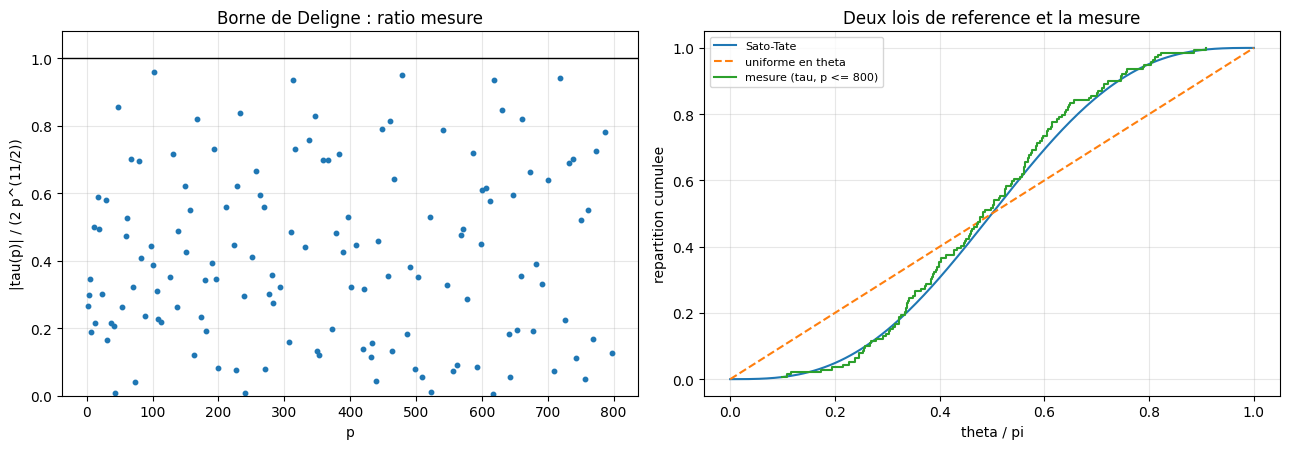

In [13]:
import matplotlib
import matplotlib.pyplot as plt

figure, (axe_gauche, axe_droite) = plt.subplots(1, 2, figsize=(13, 4.6))

axe_gauche.plot([p for _, p in ratios], [r for r, _ in ratios], "o", markersize=3.2)
axe_gauche.axhline(1.0, color="black", linewidth=1.0)
axe_gauche.set_xlabel("p")
axe_gauche.set_ylabel("|tau(p)| / (2 p^(11/2))")
axe_gauche.set_title("Borne de Deligne : ratio mesure")
axe_gauche.set_ylim(0.0, 1.08)
axe_gauche.grid(alpha=0.3)

grille = [i / 200 for i in range(201)]
axe_droite.plot(grille, [cdf_sato_tate(math.pi * x) for x in grille],
                label="Sato-Tate")
axe_droite.plot(grille, [cdf_uniforme(math.pi * x) for x in grille],
                label="uniforme en theta", linestyle="--")
empirique = [(i + 1) / len(thetas_tau) for i in range(len(thetas_tau))]
axe_droite.step([t / math.pi for t in thetas_tau], empirique, where="post",
                label="mesure (tau, p <= %d)" % N_MAX)
axe_droite.set_xlabel("theta / pi")
axe_droite.set_ylabel("repartition cumulee")
axe_droite.set_title("Deux lois de reference et la mesure")
axe_droite.legend(fontsize=8)
axe_droite.grid(alpha=0.3)

figure.tight_layout()
plt.show()

### Lecture du résultat

À gauche, les 139 rapports restent sous la droite `1` — la borne est respectée partout, le maximum mesuré valant `0.9594`. La dispersion n'est pas un bruit de calcul : c'est la variation arithmétique de `tau(p)`, celle dont la loi limite est justement l'objet du panneau de droite.

À droite, la courbe en escalier est la répartition empirique mesurée. Elle suit de près Sato–Tate et s'écarte de la droite diagonale (l'uniforme). C'est la comparaison des deux distances imprimées dans la cellule précédente qui porte le propos, pas l'allure de la figure seule — six ou cent points peuvent « avoir l'air » d'une courbe sans que ce soit un résultat.

## 9. Exercices

Trois exercices, exécutables, sans erreur volontaire : chaque bloc se termine par un `return None` et un `# TODO etudiant`, et la cellule suivante affiche le résultat courant (donc `None`) sans interrompre le carnet.

**Exercice 1 — la croissance des dimensions.** Écrire `dimensions_jusqua(k_max)` qui renvoie un dictionnaire `{k: dim S_k}` par **comptage de monômes** (pas par la formule), et le comparer à `dim_S_deux_routes`.

**Exercice 2 — la matrice oubliée.** Écrire `matrice_hecke_poids_28(p)` qui construit la matrice de `T_p` sur `S_28 = Delta * M_16` — même méthode que `matrice_hecke`, autre poids. Vérifier ensuite la récurrence `T_{p^2} = T_p^2 - p^{27}` sur cette matrice, seule relation qui se transporte d'un poids à l'autre sans changement de forme.

**Exercice 3 — la multiplicativité à la main.** Écrire `verifie_multiplicativite(limite)` qui renvoie la liste des couples `(m, n)` premiers entre eux, `m * n <= limite`, où `tau(mn) != tau(m) tau(n)`. Comparer à `multiplicativite_tau`.

In [14]:
def dimensions_jusqua(k_max):
    """Exercice 1 : {k: dim S_k} par comptage de monomes de poids k-12."""
    # TODO etudiant : boucler sur les k pairs, compter les couples (a, b) tels que 4a + 6b = k - 12
    return None


def matrice_hecke_poids_28(p):
    """Exercice 2 : matrice 2x2 de T_p sur S_28 = Delta * M_16."""
    # TODO etudiant : construire la base de S_28, puis resoudre les images comme en section 5
    return None


def verifie_multiplicativite(limite):
    """Exercice 3 : couples (m, n) premiers entre eux ou tau(mn) != tau(m) tau(n)."""
    # TODO etudiant : reutiliser gcd et DELTA_PRODUIT
    return None


for nom, resultat in (("dimensions_jusqua(30)", dimensions_jusqua(30)),
                      ("matrice_hecke_poids_28(2)", matrice_hecke_poids_28(2)),
                      ("verifie_multiplicativite(200)", verifie_multiplicativite(200))):
    if resultat is None:
        print("%-30s -> exercice a completer (None)" % nom)
    else:
        print("%-30s -> %s" % (nom, resultat))

dimensions_jusqua(30)          -> exercice a completer (None)
matrice_hecke_poids_28(2)      -> exercice a completer (None)
verifie_multiplicativite(200)  -> exercice a completer (None)


## 10. Conclusion : ce qui a été mesuré, ce qui reste cité

| Objet | Résultat |
|---|---|
| `Delta` par `(E4^3 - E6^2)/1728` **et** par `q prod (1-q^n)^24` | deux calculs, `0` écart sur `q^800` |
| `dim M_k`, `dim S_k` | formule **et** comptage de monômes : accord sur `k <= 60` |
| `T_p(E_k) = (1 + p^{k-1}) E_k` | exact sur les 10 premiers `p < 30` |
| `T_p(Delta) = tau(p) Delta` | exact, `tau(p)` lu sur l'autre route |
| `[T_p, T_q] = 0`, `T_{pq} = T_p T_q`, `T_{p^2} = T_p^2 - p^{23}` sur `S_24` | matrices entières 2×2, identités exactes |
| `|trace T_p| <= 4 p^{11.5}` et `|det T_p| <= 4 p^{23}` sur `S_24` | respectés pour les 6 premiers `p` ; `det = p^{23}` est **faux** (mesuré) |
| borne de Deligne `|tau(p)| <= 2 p^{11/2}` | respectée sur les 139 premiers `p <= 800`, sans violation (max 0,96 de la borne, `p = 103`) |
| `tau(mn) = tau(m) tau(n)` et récurrence de Hecke | exacts sur la troncature |
| Sato–Tate | **exploré** : distance sup mesurée, comparaison à l'uniforme, échantillon trop petit pour conclure |

**Ce que le carnet ne fait pas** : il ne prouve ni Deligne 1974, ni Sato–Tate, ni l'existence d'une base de formes propres. Il ne calcule aucune fonction `L` et ne touche pas aux formes de niveau supérieur. Il mesure des identités sur une troncature, exactement, et signale chaque fois qu'un énoncé est cité plutôt que vérifié.

**Ce qu'il ouvre** : la même machinerie, appliquée à un niveau `N > 1`, produit les formes paraboliques de congruences et leurs algèbres de Hecke — les objets du programme de Serre sur les représentations galoisiennes, et le lieu où `tau(p)` devient une trace de Frobenius.
